In [148]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/karolinasienko/eds220-hwk3


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

In [149]:
# FINAL CODE

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

#### First Dataset: New York State Oil Spills

> This data is provided by the New York State Department of Environmental Conservation. The dataset contains records of spills of petroleum and other hazardous materials in New York State. Under State law and regulations, spills that could pollute the lands or waters of the state must be reported by the spiller and, in some cases, by anyone who has knowledge of the spill. Each spill record includes administrative information (DEC region and unique seven-digit spill number), program facility name, spill date/time, location, spill source and cause, type of material(s) spilled, quantity spilled and recoverd, units measured, surface water bodies affected, close date (cleanup activity finished).

> **Date of Access:** October 31, 2026

> **Source:** New York State Department of Environmental Conservation. (n.d.). *Spill incidents* [Data set]. NY Open Data. Retrieved October 31, 2026. https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk



#### Second Dataset: 2026 TIGER/Line Shapefiles: Counties (and equivalent)

> The 2026 TIGER/Line shapefile is provided by the U.S. Census Bureau. It contains boundaries for counties and county-equivalent entities in the United States, such as parishes in Louisiana, boroughs, municipalities, and census areas in Alaska, independent cities in Maryland, Missouri, Nevada, and Virginia, and similar divisions in U.S. territories. The entire area of the United States, Puerto Rico, and the Island Areas is covered by counties or equivalent entities. The boundaries for counties and equivalent entities are mostly current as of January 1, 2026, as reported through the Census Bureau's Boundary and Annexation Survey.

> **Date of Access:** October 31, 2026

> **Source:** U.S. Census Bureau. (2026). *TIGER/Line shapefiles: Counties and equivalent entities* [Data set]. Retrieved October 31, 2026. https://www.census.gov/cgi-bin/geo/shapefiles/index.php?year=2026&layergroup=Counties%20%28and%20equivalent%29

## 3. Import libraries

In [150]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [151]:
fp = os.path.join('data', 'Spill_Incidents_20261031.csv')
spills = pd.read_csv(fp)

fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

>Below, the attribute and methods `.head()`, `.dtypes`, `.unique()`, `.nunique()`, and `.info()` were used for preliminary data exploraiton. From `.info()`, we know that the `spills` dataframe has 574,655 rows and 20 columns. Half of the columns contain null values, and only three of the column types are integer while all the rest are the type object. Using `.unique()` and `.nunique()`, we found out that there are three specific material families, as well as an "Other" value, and there are 87 distinct values listed in the `County` column. 

In [152]:
#a. Check the dataframe's head
spills.head()

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6


In [153]:
#b. Check the data types of the columns
spills.dtypes

Spill Number              int64
Program Facility Name    object
Street 1                 object
Street 2                 object
Locality                 object
County                   object
ZIP Code                 object
SWIS Code                 int64
DEC Region                int64
Spill Date               object
Received Date            object
Contributing Factor      object
Waterbody                object
Source                   object
Close Date               object
Material Name            object
Material Family          object
Quantity                 object
Units                    object
Recovered                object
dtype: object

In [154]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [155]:
#d. Check the unique values in the `county` column
print(spills['County'].unique())
print(spills['County'].nunique())

['Westchester' 'Queens' 'Bronx' 'Sullivan' 'Cortland' 'New York' 'Ulster'
 'Kings' 'Orange' 'Dutchess' 'Onondaga' 'Saratoga' 'Cayuga' 'Oswego'
 'Warren' 'Niagara' 'Rockland' 'Nassau' 'Jefferson' 'Schenectady' 'Albany'
 'Monroe' 'Schuyler' 'St Lawrence' 'Richmond' 'Clinton' 'Lewis' 'Essex'
 'Chenango' 'Erie' 'Livingston' 'Oneida' 'Wayne' 'Suffolk' 'Orleans'
 'Ontario' 'Genesee' 'Otsego' 'Tompkins' 'Madison' 'Chemung' 'Seneca'
 'Broome' 'Hamilton' 'Washington' 'Steuben' 'Rensselaer' 'Franklin'
 'Columbia' 'Fulton' 'Herkimer' 'Schoharie' 'Montgomery' 'Putnam'
 'Delaware' 'New Jersey - Region 2' 'Tioga' 'Chautauqua' 'Cattaraugus'
 'Wyoming' 'Yates' 'Greene' 'Pennsylvania - Region 9' 'Allegany'
 'New Jersey - Region 3 (N)' 'Cattaraugus Indian Reservation'
 'Connecticut - Region 3 (T)' 'New Jersey - Region 3 (T)'
 'Canada - Region 6' 'Canada - Region 9' 'Pennsylvania - Region 8'
 'Vermont - Region 5 (R)' 'Vermont - Region 4'
 'Connecticut - Region 3 (N)' 'Pennsylvania - Region 3'
 'Tuscarora

In [156]:
spills.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574655 entries, 0 to 574654
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   Spill Number           574655 non-null  int64 
 1   Program Facility Name  574649 non-null  object
 2   Street 1               574521 non-null  object
 3   Street 2               44733 non-null   object
 4   Locality               573505 non-null  object
 5   County                 574655 non-null  object
 6   ZIP Code               57888 non-null   object
 7   SWIS Code              574655 non-null  int64 
 8   DEC Region             574655 non-null  int64 
 9   Spill Date             574504 non-null  object
 10  Received Date          574152 non-null  object
 11  Contributing Factor    574655 non-null  object
 12  Waterbody              47989 non-null   object
 13  Source                 574655 non-null  object
 14  Close Date             562289 non-null  object
 15  

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [157]:
# Making column names all lower and snake case
spills.columns = spills.columns.str.lower()
spills.columns = spills.columns.str.replace(' ', '_')

spills.columns

Index(['spill_number', 'program_facility_name', 'street_1', 'street_2',
       'locality', 'county', 'zip_code', 'swis_code', 'dec_region',
       'spill_date', 'received_date', 'contributing_factor', 'waterbody',
       'source', 'close_date', 'material_name', 'material_family', 'quantity',
       'units', 'recovered'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [158]:
# Update spill_date, received_date, close_date columns to datetime
cols_list = ['spill_date', 'received_date', 'close_date']
for col in cols_list:
    spills[col] = pd.to_datetime(spills[col])

# Update quantity to float
spills['quantity'] = spills['quantity'].str.replace(',','').astype(float)
    
# Update recovered to float (get rid of commas first)
spills['recovered'] = spills['recovered'].str.replace(',','').astype(float)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [159]:
# Selecting data about petroleum spills in 2023
petr_23 = spills[(spills['material_family'] == 'Petroleum') & (spills['spill_date'] >= '2023-01-01') & (spills['spill_date'] <= '2023-12-31')]


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [160]:
# Verify that petr_23 only has data for 2023 and from January through December
print(f"The dataframe only has dates from the year {petr_23['spill_date'].dt.year.unique()} and has the months from {petr_23['spill_date'].dt.month.min()} to {petr_23['spill_date'].dt.month.max()}.")

The dataframe only has dates from the year [2023] and has the months from 1 to 12.


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [161]:
# Checking that petr_23 only has petroleum spill data
assert petr_23['material_family'].unique() == 'Petroleum'

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

In [162]:
print(f"The dataframe petr_23 has {len(petr_23)} rows and {petr_23['spill_number'].nunique()} unique spills.")

The dataframe petr_23 has 8468 rows and 8228 unique spills.


> These numbers are not the same. There are less unique spill numbers than the number of rows in `petr_23`. The spill number is the "program-specific spill identification number", so it may be because multiple observations for the same oil spill were recorded.

<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [163]:
# New df with number of petroleum spills per county in 2023
spills_per_county = petr_23.groupby('county', as_index=False).nunique()[['county', 'spill_number']].rename(columns={'spill_number': 'n_spills'})

In [164]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

> Below, the attribute and methods `.head()`, `.dtypes`, `.crs`, `.plot()`, and `.info()` were used for preliminary data exploration. From `.info()`, we know that the `counties` dataframe has 3235 rows and 19 columns. Only 3 of the columns contain null values, and only two of the columns are of type integer while all the rest are of type object. The attribute `.crs()` gives information on the CRS of this spatial data, which is EPSG:4269. Plotting the geo-dataframe with `.plot()` shows the entire United States, including territories like Puerto Rico and Guam.

In [165]:
# a
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [166]:
# b
counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [167]:
# c
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

<Axes: >

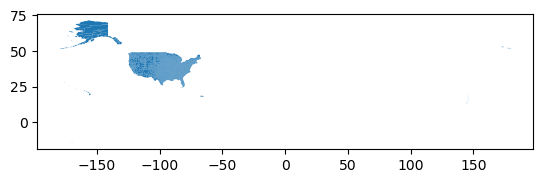

In [168]:
# d
counties.plot()

In [169]:
# Printing relevant info
counties.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 3235 entries, 0 to 3234
Data columns (total 19 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   STATEFP   3235 non-null   object  
 1   COUNTYFP  3235 non-null   object  
 2   COUNTYNS  3235 non-null   object  
 3   GEOID     3235 non-null   object  
 4   GEOIDFQ   3235 non-null   object  
 5   NAME      3235 non-null   object  
 6   NAMELSAD  3235 non-null   object  
 7   LSAD      3235 non-null   object  
 8   CLASSFP   3235 non-null   object  
 9   MTFCC     3235 non-null   object  
 10  CSAFP     1341 non-null   object  
 11  CBSAFP    1915 non-null   object  
 12  METDIVFP  139 non-null    object  
 13  FUNCSTAT  3235 non-null   object  
 14  ALAND     3235 non-null   int64   
 15  AWATER    3235 non-null   int64   
 16  INTPTLAT  3235 non-null   object  
 17  INTPTLON  3235 non-null   object  
 18  geometry  3235 non-null   geometry
dtypes: geometry(1), int64(2), object(16)
mem

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [170]:
# Making column names all lower case
counties.columns = counties.columns.str.lower()
counties.columns

Index(['statefp', 'countyfp', 'countyns', 'geoid', 'geoidfq', 'name',
       'namelsad', 'lsad', 'classfp', 'mtfcc', 'csafp', 'cbsafp', 'metdivfp',
       'funcstat', 'aland', 'awater', 'intptlat', 'intptlon', 'geometry'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

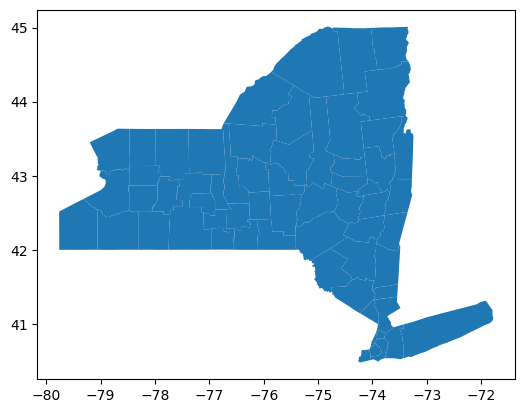

In [171]:
# NY statefp code is 36 - selecting rows with this number
ny_counties = counties[counties['statefp'] == '36']

# Plotting NY counties
ny_counties.plot();

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [172]:
# Printing distinct county names
print(ny_counties['name'].unique()) # 62 rows

['Erie' 'Niagara' 'Jefferson' 'Steuben' 'Seneca' 'Rensselaer' 'Albany'
 'Saratoga' 'Schoharie' 'Schenectady' 'Ulster' 'Dutchess' 'Orange'
 'Columbia' 'Tompkins' 'Tioga' 'Broome' 'Cayuga' 'Genesee' 'Onondaga'
 'Oswego' 'Madison' 'Livingston' 'Monroe' 'Ontario' 'Orleans' 'Wayne'
 'Chautauqua' 'Sullivan' 'Chemung' 'Cattaraugus' 'Fulton' 'Montgomery'
 'Cortland' 'Warren' 'Washington' 'Otsego' 'Queens' 'Bronx' 'Nassau'
 'Westchester' 'Richmond' 'Kings' 'Suffolk' 'Rockland' 'New York' 'Putnam'
 'Clinton' 'St. Lawrence' 'Herkimer' 'Oneida' 'Yates' 'Greene' 'Schuyler'
 'Delaware' 'Hamilton' 'Lewis' 'Allegany' 'Chenango' 'Wyoming' 'Franklin'
 'Essex']


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [173]:
# Printing distinct county names
print(spills_per_county['county'].unique()) # 66 rows

# There are 66 unique county names in this dataframe vs ny_counties.

['Albany' 'Allegany' 'Bronx' 'Broome' 'Cattaraugus' 'Cayuga' 'Chautauqua'
 'Chemung' 'Chenango' 'Clinton' 'Columbia' 'Cortland' 'Delaware'
 'Dutchess' 'Erie' 'Essex' 'Franklin' 'Fulton' 'Genesee' 'Greene'
 'Hamilton' 'Herkimer' 'Jefferson' 'Kings' 'Lewis' 'Livingston' 'Madison'
 'Monroe' 'Montgomery' 'Nassau' 'New Jersey - Region 2' 'New York'
 'Niagara' 'Oneida' 'Onondaga' 'Onondaga Indian Reservation' 'Ontario'
 'Orange' 'Orleans' 'Oswego' 'Otsego' 'Pennsylvania - Region 3' 'Putnam'
 'Queens' 'Rensselaer' 'Richmond' 'Rockland' 'Saratoga' 'Schenectady'
 'Schoharie' 'Schuyler' 'Seneca' 'St Lawrence' 'Steuben' 'Suffolk'
 'Sullivan' 'Tioga' 'Tompkins' 'Tuscarora Indian Reservation' 'Ulster'
 'Warren' 'Washington' 'Wayne' 'Westchester' 'Wyoming' 'Yates']


<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [174]:
diff_names_spills = np.setdiff1d(spills_per_county['county'], ny_counties['name'])
diff_names_spills

array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'St Lawrence',
       'Tuscarora Indian Reservation'], dtype=object)

In [175]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [176]:
diff_names_ny = np.setdiff1d(ny_counties['name'], spills_per_county['county'])
diff_names_ny

array(['St. Lawrence'], dtype=object)

In [177]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [178]:
# Number of spills in each reservation
tuscarora = spills_per_county.loc[spills_per_county['county'] == 'Tuscarora Indian Reservation', 'n_spills'].sum()
onondaga = spills_per_county.loc[spills_per_county['county'] == 'Onondaga Indian Reservation', 'n_spills'].sum()

print(f"Tuscarora Indian Reservation has {tuscarora} spills.")
print(f"Onondaga Indian Reservation has {onondaga} spills.")

Tuscarora Indian Reservation has 2 spills.
Onondaga Indian Reservation has 1 spills.


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [179]:
# Updating St Lawrence county name
dict = {'St Lawrence' : 'St. Lawrence'}
spills_per_county['county'] = spills_per_county['county'].replace(dict)

# Verifying the update was successful
assert 'St. Lawrence' in spills_per_county['county'].values

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [180]:
# Renaming column name to match for the join
ny_counties = ny_counties.rename(columns={'name':'county'})

b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [181]:
# Inner joining dataframes
ny_spills = pd.merge(ny_counties, spills_per_county, how='inner', on='county')
ny_spills

,statefp,countyfp,countyns,geoid,geoidfq,county,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry,n_spills
0,36,029,00974113,36029,0500000US36029,Erie,Erie County,06,H1,G4020,160,15380,None,A,2700743371,476876406,+42.7527590,-078.7781922,"POLYGON ((-78.77760 42.46188, -78.77756 42.461...",320
1,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084...",97
2,36,045,00974121,36045,0500000US36045,Jefferson,Jefferson County,06,H1,G4020,None,48060,None,A,3283928401,1524534721,+43.9963890,-076.0529678,"POLYGON ((-75.90417 43.69796, -75.90437 43.697...",114
3,36,101,00974148,36101,0500000US36101,Steuben,Steuben County,06,H1,G4020,236,18500,None,A,3601403364,35034920,+42.2667252,-077.3855253,"POLYGON ((-77.08327 42.00002, -77.09391 41.999...",77
4,36,099,00974147,36099,0500000US36099,Seneca,Seneca County,06,H1,G4020,464,42900,None,A,838377561,172813845,+42.7822943,-076.8270880,"POLYGON ((-76.96393 43.01284, -76.96393 43.012...",27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,36,003,00974100,36003,0500000US36003,Allegany,Allegany County,06,H1,G4020,None,None,None,A,2666410162,12989705,+42.2478532,-078.0261531,"POLYGON ((-78.04342 42.51846, -78.04326 42.518...",32
58,36,017,00974107,36017,0500000US36017,Chenango,Chenango County,06,H1,G4020,None,None,None,A,2314006867,13433903,+42.4780238,-075.6022407,"POLYGON ((-75.40346 42.50870, -75.40331 42.508...",44
59,36,121,00974158,36121,0500000US36121,Wyoming,Wyoming County,06,H1,G4020,None,None,None,A,1535086368,9085227,+42.7013652,-078.2285762,"POLYGON ((-77.95538 42.71354, -77.95537 42.713...",27
60,36,033,00974115,36033,0500000US36033,Franklin,Franklin County,06,H1,G4020,None,None,None,A,4219867377,176612003,+44.5943758,-074.3106700,"POLYGON ((-74.38487 44.11157, -74.38667 44.111...",55


<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [182]:
# Counties that were dropped by the inner join
dropped_counties = np.setdiff1d(spills_per_county['county'], ny_spills['county'])

# Finding number of spills for each dropped county
for county in dropped_counties:
    dropped_spill_num = spills_per_county.loc[spills_per_county['county'] == county, 'n_spills'].sum()
    print(f"{county} was dropped by the inner join and had {dropped_spill_num} spills.")

New Jersey - Region 2 was dropped by the inner join and had 7 spills.
Onondaga Indian Reservation was dropped by the inner join and had 1 spills.
Pennsylvania - Region 3 was dropped by the inner join and had 1 spills.
Tuscarora Indian Reservation was dropped by the inner join and had 2 spills.


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

> Dropping these records does not affect the map we will report, but it does affect the information we will report. Tuscarora Indian Reservation is located within Niagara County and Onondaga Indian Reservation is located within Onondaga county, so exxcluding those spills underrepresents those two counties. The records for New Jersey and Pennsylvania have data on spills that also affected these areas, but because they are outside New York’s county boundaries, excluding them from a county-level map is reasonable.

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [183]:
# Getting the number of spills in Tuscarora
num_spills_tuscarora = spills_per_county.loc[spills_per_county['county'] == 'Tuscarora Indian Reservation', 'n_spills'].sum()

# Adding these spills to Niagara county in ny_spills
ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] = ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] + num_spills_tuscarora


# Getting the number of spills in Onondaga
num_spills_onondaga = spills_per_county.loc[spills_per_county['county'] == 'Onondaga Indian Reservation', 'n_spills'].sum()

# Adding these spills to Onondaga county in ny_spills
ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] = ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] + num_spills_onondaga


## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



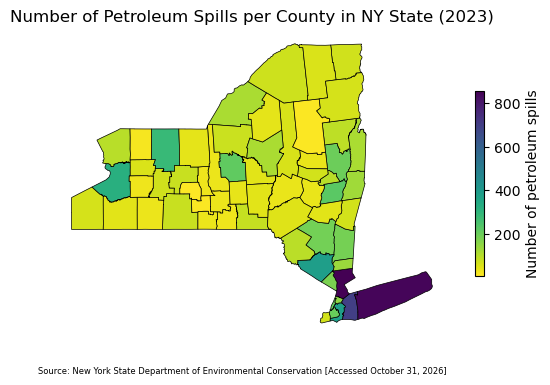

In [239]:
# Initialize figure and axis
fig, ax = plt.subplots()

# Plotting spills
ny_spills.plot(column = 'n_spills',
               cmap = 'viridis_r',
               edgecolor = 'Black',
               linewidth = 0.5,
               legend = True,
               legend_kwds={'label': 'Number of petroleum spills', 'shrink' : 0.5},
               ax = ax)

# Adding a title
ax.set_title('Number of Petroleum Spills per County in NY State (2023)')

# Removing the axis
ax.axis('off')

# Adding the data source
fig.text(0.1, 0.1, 'Source: New York State Department of Environmental Conservation [Accessed October 31, 2026]', fontsize = 6)

plt.show()

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.